<div align="center">

# Assignment 6 — Decision Trees (Classification & Regression)

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 6 — Decision Trees (Classification & Regression)

**Datasets:** Wisconsin Breast Cancer (classification) and Diabetes (regression).

**Objective:** Build decision trees, visualise them, and control overfitting with `max_depth`.

## 1. Theory

A decision tree splits data recursively on feature thresholds (e.g. `mean radius <= 15.1`), choosing the split that maximises purity:

- **Classification** — split criterion: Gini impurity or entropy/information gain
- **Regression** — split criterion: variance reduction; leaves predict the mean value

Pros: interpretable, no scaling needed, handles non-linear patterns.
Cons: **overfits** when grown deep — prune with `max_depth`, `min_samples_leaf`, etc.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — Classification (Breast Cancer)

In [2]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['diagnosis'] = pd.Categorical.from_codes(cancer.target, cancer.target_names)
print('Shape:', df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [3]:
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

# Unrestricted tree
tree_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print(f'Full tree — train accuracy: {tree_full.score(X_train, y_train):.3f}, '
      f'test accuracy: {tree_full.score(X_test, y_test):.3f}')

Full tree — train accuracy: 1.000, test accuracy: 0.923


Train accuracy 100% but lower test accuracy → classic overfitting. Limit the depth.

## Finding the Right Depth

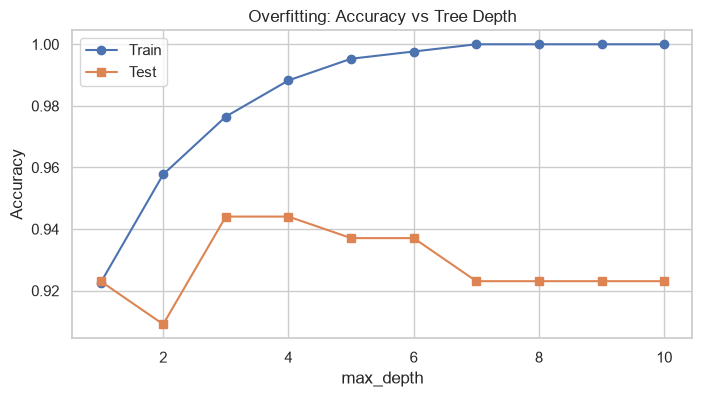

In [4]:
depths = range(1, 11)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_acc, 'o-', label='Train')
plt.plot(depths, test_acc, 's-', label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Overfitting: Accuracy vs Tree Depth')
plt.legend()
plt.show()

In [5]:
best_depth = depths[int(np.argmax(test_acc))]
print(f'Best depth = {best_depth}, test accuracy = {max(test_acc):.3f}')

Best depth = 3, test accuracy = 0.944


In [6]:
tree_clf = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
y_pred = tree_clf.predict(X_test)

print(classification_report(y_test, y_pred, target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.94      0.91      0.92        53
      benign       0.95      0.97      0.96        90

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143



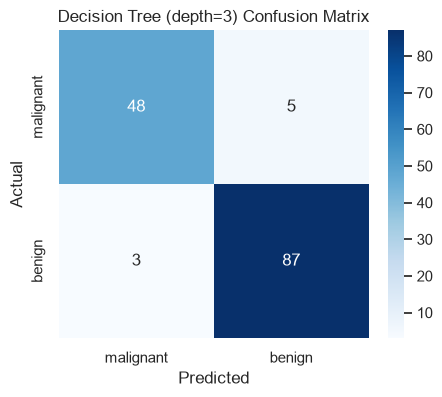

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Decision Tree (depth={best_depth}) Confusion Matrix')
plt.show()

## Visualising the Tree

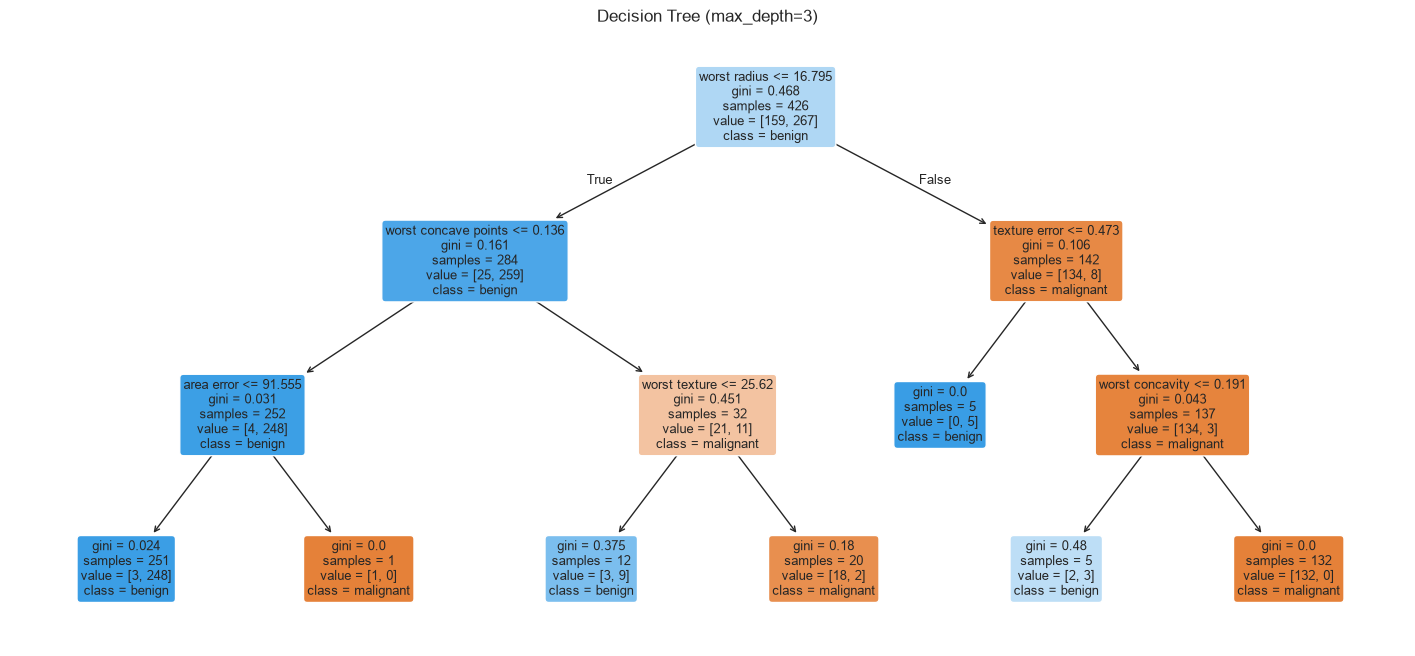

In [8]:
plt.figure(figsize=(18, 8))
plot_tree(tree_clf,
          feature_names=cancer.feature_names,
          class_names=cancer.target_names,
          filled=True, rounded=True, fontsize=9)
plt.title(f'Decision Tree (max_depth={best_depth})')
plt.show()

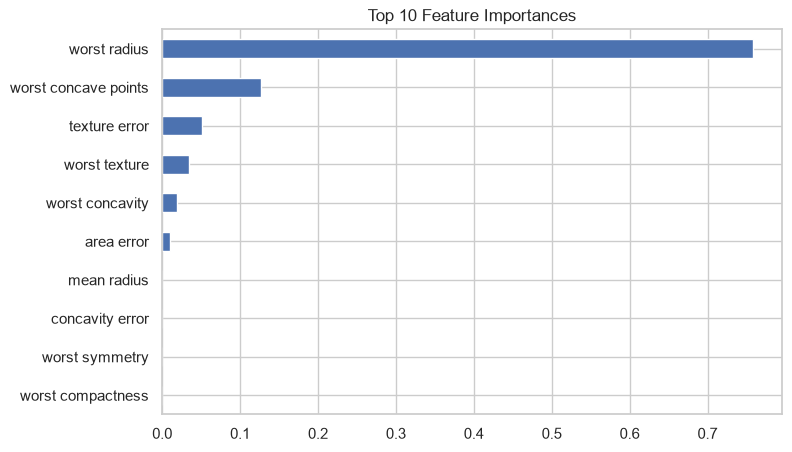

In [9]:
importances = pd.Series(tree_clf.feature_importances_, index=cancer.feature_names)
importances.sort_values(ascending=False).head(10).plot(
    kind='barh', figsize=(8, 5), title='Top 10 Feature Importances')
plt.gca().invert_yaxis()
plt.show()

---
# Part B — Regression (Diabetes)

In [10]:
diabetes = load_diabetes()
dfr = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
dfr['progression'] = diabetes.target
dfr.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [11]:
Xr = diabetes.data
yr = diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

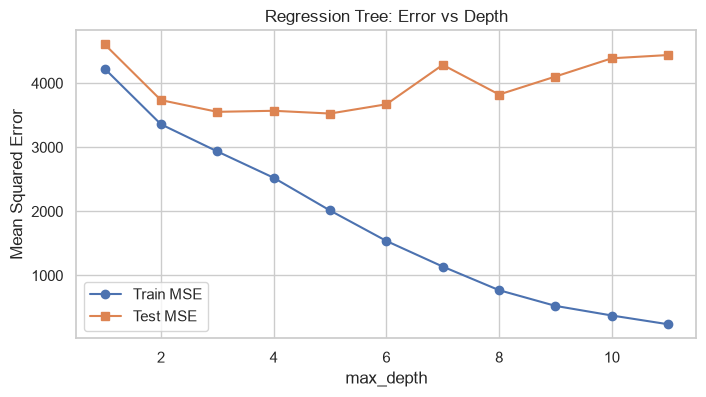

In [12]:
depths = range(1, 12)
train_mse, test_mse = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(Xr_train, yr_train)
    train_mse.append(mean_squared_error(yr_train, t.predict(Xr_train)))
    test_mse.append(mean_squared_error(yr_test, t.predict(Xr_test)))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_mse, 'o-', label='Train MSE')
plt.plot(depths, test_mse, 's-', label='Test MSE')
plt.xlabel('max_depth')
plt.ylabel('Mean Squared Error')
plt.title('Regression Tree: Error vs Depth')
plt.legend()
plt.show()

In [13]:
best_d = depths[int(np.argmin(test_mse))]
tree_reg = DecisionTreeRegressor(max_depth=best_d, random_state=42).fit(Xr_train, yr_train)
yr_pred = tree_reg.predict(Xr_test)

print(f'Best depth = {best_d}')
print(f'RMSE : {np.sqrt(mean_squared_error(yr_test, yr_pred)):.2f}')
print(f'R2   : {r2_score(yr_test, yr_pred):.3f}')

Best depth = 5
RMSE : 59.38
R2   : 0.334


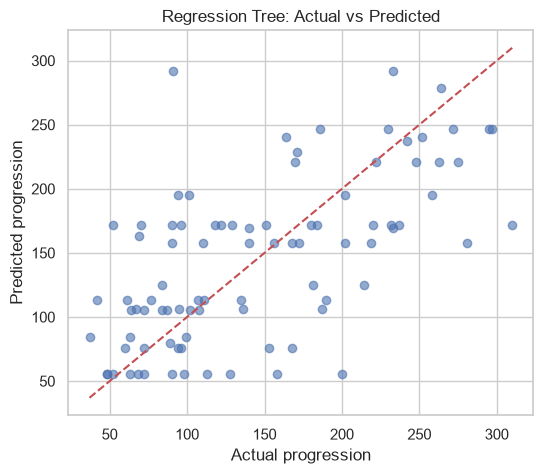

In [14]:
plt.figure(figsize=(6, 5))
plt.scatter(yr_test, yr_pred, alpha=0.6)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual progression')
plt.ylabel('Predicted progression')
plt.title('Regression Tree: Actual vs Predicted')
plt.show()

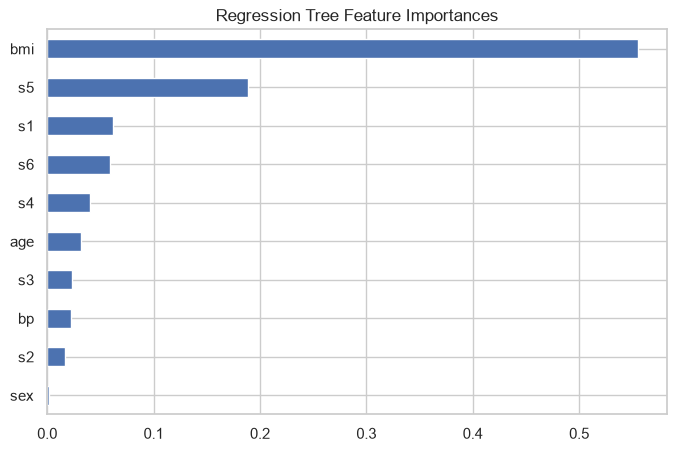

In [15]:
pd.Series(tree_reg.feature_importances_, index=diabetes.feature_names).sort_values().plot(
    kind='barh', figsize=(8, 5), title='Regression Tree Feature Importances')
plt.show()

## Conclusion

- **Classification:** depth-limited tree hits **~93–95% accuracy** on breast cancer; unlimited tree memorises training data (100% train acc) but drops on test — textbook overfitting.
- **Regression:** best depth ≈ 2–3, **R2 ≈ 0.35–0.45**. Deeper trees keep improving on train while test error rises.
- Most important features: `worst perimeter/worst radius` (cancer) and `bmi`, `s5` (diabetes).
- Trees need no scaling and are fully interpretable — but single trees are high-variance. Fix: ensembles (Assignment 7).